# CISI Information Retrieval System
## TF-IDF Vector Space Model with Cosine Similarity

This notebook implements a basic Information Retrieval (IR) system using the CISI collection.

### Architecture
**CISI Documents → Parsing → Preprocessing → TF-IDF Index → Query Preprocessing → Cosine Similarity → Ranked Results → Evaluation**

### Main techniques
- Lowercasing
- Alphabetic tokenization
- English stopword removal
- Porter stemming
- TF-IDF indexing
- Vector Space Model
- Cosine similarity ranking
- Precision@10, Recall@10, F1@10, Average Precision, and MAP


In [1]:
# Import libraries
from pathlib import Path
import re
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity

try:
    from nltk.stem import PorterStemmer
    stemmer = PorterStemmer()
except Exception:
    stemmer = None

# Put CISI.ALL, CISI.QRY, and CISI.REL in the same folder as this notebook.
DATA_DIR = Path(".")
ALL_FILE = DATA_DIR / "CISI.ALL"
QRY_FILE = DATA_DIR / "CISI.QRY"
REL_FILE = DATA_DIR / "CISI.REL"


## 1. Load and Parse the CISI Dataset

In [2]:
def parse_cisi_records(path):
    records = {}
    current_id = None
    current_field = None

    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for raw in f:
            line = raw.rstrip("\n")

            if line.startswith(".I "):
                current_id = int(line.split()[1])
                records[current_id] = {"T": [], "A": [], "W": [], "X": []}
                current_field = None

            elif line in {".T", ".A", ".W", ".X"}:
                current_field = line[1]

            elif current_id is not None and current_field is not None:
                records[current_id][current_field].append(line.strip())

    for rid, fields in records.items():
        for field in fields:
            fields[field] = " ".join(fields[field]).strip()

    return records

def parse_relevance(path):
    relevance = defaultdict(set)
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            parts = line.split()
            if len(parts) >= 2:
                relevance[int(parts[0])].add(int(parts[1]))
    return dict(relevance)

documents_raw = parse_cisi_records(ALL_FILE)
queries_raw = parse_cisi_records(QRY_FILE)
relevance = parse_relevance(REL_FILE)

print("Documents:", len(documents_raw))
print("Queries:", len(queries_raw))
print("Queries with relevance judgments:", len(relevance))


Documents: 1460
Queries: 112
Queries with relevance judgments: 76


## 2. Inspect a Document and Query

In [3]:
print("DOCUMENT 1")
print("Title:", documents_raw[1]["T"])
print("Author:", documents_raw[1]["A"])
print("Text:", documents_raw[1]["W"][:700])

print("\nQUERY 1")
print(queries_raw[1]["W"])
print("\nKnown relevant document IDs:")
print(sorted(relevance.get(1, set())))


DOCUMENT 1
Title: 18 Editions of the Dewey Decimal Classifications
Author: Comaromi, J.P.
Text: The present study is a history of the DEWEY Decimal Classification.  The first edition of the DDC was published in 1876, the eighteenth edition in 1971, and future editions will continue to appear as needed.  In spite of the DDC's long and healthy life, however, its full story has never been told.  There have been biographies of Dewey that briefly describe his system, but this is the first attempt to provide a detailed history of the work that more than any other has spurred the growth of librarianship in this country and abroad.

QUERY 1
What problems and concerns are there in making up descriptive titles? What difficulties are involved in automatically retrieving articles from approximate titles? What is the usual relevance of the content of articles to their titles?

Known relevant document IDs:
[28, 35, 38, 42, 43, 52, 65, 76, 86, 150, 189, 192, 193, 195, 215, 269, 291, 320, 429, 465, 46

## 3. Text Preprocessing

The same preprocessing is applied to documents and user queries:
1. Convert text to lowercase.
2. Keep alphabetic tokens.
3. Remove common English stopwords.
4. Apply Porter stemming.

Using the same transformation for documents and queries ensures that they are represented consistently.

In [4]:
stop_words = set(ENGLISH_STOP_WORDS)

def preprocess(text):
    text = text.lower()
    tokens = re.findall(r"[a-z]+", text)
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    if stemmer is not None:
        tokens = [stemmer.stem(t) for t in tokens]
    return " ".join(tokens)

example = queries_raw[1]["W"]
print("BEFORE:\n", example)
print("\nAFTER:\n", preprocess(example))


BEFORE:
 What problems and concerns are there in making up descriptive titles? What difficulties are involved in automatically retrieving articles from approximate titles? What is the usual relevance of the content of articles to their titles?

AFTER:
 problem concern make descript titl difficulti involv automat retriev articl approxim titl usual relev content articl titl


## 4. Build the TF-IDF Index

In [5]:
doc_ids = sorted(documents_raw)

documents = [
    " ".join(
        x for x in [documents_raw[did]["T"], documents_raw[did]["W"]] if x
    )
    for did in doc_ids
]

processed_documents = [preprocess(doc) for doc in documents]

vectorizer = TfidfVectorizer(
    lowercase=False,
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    norm="l2"
)

tfidf_matrix = vectorizer.fit_transform(processed_documents)

print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Number of documents:", tfidf_matrix.shape[0])
print("Vocabulary size:", tfidf_matrix.shape[1])


TF-IDF matrix shape: (1460, 5543)
Number of documents: 1460
Vocabulary size: 5543


## 5. Retrieval Model: Cosine Similarity

A query is preprocessed and transformed with the fitted TF-IDF vectorizer. Cosine similarity compares the query vector with every document vector. Documents are sorted from highest to lowest similarity score.

In [6]:
def search(query, top_k=10):
    processed_query = preprocess(query)
    query_vector = vectorizer.transform([processed_query])

    similarities = cosine_similarity(
        query_vector, tfidf_matrix
    ).flatten()

    ranked_indices = np.argsort(-similarities)[:top_k]

    results = []
    for rank, idx in enumerate(ranked_indices, start=1):
        did = doc_ids[idx]
        results.append({
            "Rank": rank,
            "Document_ID": did,
            "Similarity": similarities[idx],
            "Title": documents_raw[did]["T"],
            "Snippet": documents_raw[did]["W"][:250]
        })

    return pd.DataFrame(results)


## 6. Test the Search Engine

In [7]:
test_query = "What is information science?"
results = search(test_query, top_k=10)

print("Query:", test_query)
display(results)


Query: What is information science?


,Rank,Document_ID,Similarity,Title,Snippet
0,1,469,0.604074,The Phenomena of Interest to Information Science,Discusses the various explicit and implicit de...
1,2,599,0.520874,On the Evaluation of Information Science,The emergence and development of information s...
2,3,85,0.488375,Information Science: Toward the Development of...,It is pointed out that if information science ...
3,4,456,0.487294,Information and Its User,In science and technology user studies are num...
4,5,1142,0.473025,Science on science - Introduction to a general...,This book generalizes world and soviet experie...
5,6,1030,0.471430,"Little Science, Big Science",Pegram lecturers are supposed to talk about sc...
6,7,640,0.436738,The Scientific Premises of Information Science,Throughout my years of work as an information ...
7,8,60,0.431777,Information Science: What Is It?,"In seeking a new sense of identity, we ask, in..."
8,9,137,0.404617,Information Needs and Uses,Information science meets behavioral science i...
9,10,535,0.379262,"Information Systems, Services, and Centers",This book is concerned with the practices of i...


## 7. Search Using an Original CISI Query

In [8]:
query_id = 1
query_text = queries_raw[query_id]["W"]

print("CISI Query ID:", query_id)
print(query_text)

results = search(query_text, top_k=10)
display(results)

print("Known relevant documents:")
print(sorted(relevance.get(query_id, set())))


CISI Query ID: 1
What problems and concerns are there in making up descriptive titles? What difficulties are involved in automatically retrieving articles from approximate titles? What is the usual relevance of the content of articles to their titles?


,Rank,Document_ID,Similarity,Title,Snippet
0,1,722,0.418260,Information Transfer Limitations of Titles of ...,Some methods of estimating the minimum amounts...
1,2,429,0.390898,The Information Content of Titles in Engineeri...,Since many alerting and information services r...
2,3,589,0.361073,Are Titles of Chemical Papers Becoming More In...,The efficiency of key-work-in-context (KWIC) p...
3,4,603,0.294035,The Efficiency of MEDLARS Titles for Retrieval,Previous research has indicated that the title...
4,5,1281,0.267645,Relative Effectiveness of Document Titles and ...,Abstract. Individuals who received documents ...
5,6,711,0.246087,"Development and Production of Chemical Titles,...",The introduction of Chemical titles in 1961 ma...
6,7,813,0.237024,"Comparative Efficiency of Searching Titles, Ab...",The choice of the suitable data base for provi...
7,8,1299,0.233111,Current Physics Information,A new concept in science communication will be...
8,9,650,0.229685,"Relative Effectiveness of Titles, Abstracts, a...",We have investigated the relative merits of se...
9,10,38,0.221963,Machinelike Indexing by People,A study of several thousand entries in a class...


Known relevant documents:
[28, 35, 38, 42, 43, 52, 65, 76, 86, 150, 189, 192, 193, 195, 215, 269, 291, 320, 429, 465, 466, 482, 483, 510, 524, 541, 576, 582, 589, 603, 650, 680, 711, 722, 726, 783, 813, 820, 868, 869, 894, 1162, 1164, 1195, 1196, 1281]


## 8. Evaluation

For each query, the retrieved ranking is compared with `CISI.REL`.

- **Precision@10:** proportion of the top 10 retrieved documents that are relevant.
- **Recall@10:** proportion of all known relevant documents retrieved in the top 10.
- **F1@10:** harmonic mean of Precision@10 and Recall@10.
- **Average Precision (AP):** averages precision values at ranks where relevant documents occur.
- **MAP:** mean AP over evaluated queries.

In [9]:
def average_precision(ranked_ids, relevant_ids):
    if not relevant_ids:
        return np.nan

    hits = 0
    precision_sum = 0.0

    for rank, doc_id in enumerate(ranked_ids, start=1):
        if doc_id in relevant_ids:
            hits += 1
            precision_sum += hits / rank

    return precision_sum / len(relevant_ids)

def evaluate_query(query_id, k=10):
    query_text = queries_raw[query_id]["W"]
    query_vector = vectorizer.transform([preprocess(query_text)])
    scores = cosine_similarity(query_vector, tfidf_matrix).flatten()

    ranked_indices = np.argsort(-scores)
    ranked_ids = [doc_ids[i] for i in ranked_indices]
    top_k_ids = ranked_ids[:k]

    relevant_ids = relevance.get(query_id, set())
    hits = sum(doc_id in relevant_ids for doc_id in top_k_ids)

    precision = hits / k
    recall = hits / len(relevant_ids) if relevant_ids else np.nan

    if precision + recall > 0:
        f1 = 2 * precision * recall / (precision + recall)
    else:
        f1 = 0.0

    ap = average_precision(ranked_ids, relevant_ids)

    return {
        "Query_ID": query_id,
        f"Precision@{k}": precision,
        f"Recall@{k}": recall,
        f"F1@{k}": f1,
        "Average_Precision": ap,
        "Relevant_Documents": len(relevant_ids),
        f"Relevant_in_Top_{k}": hits
    }

evaluation_query_ids = sorted(set(queries_raw).intersection(relevance))

evaluation_df = pd.DataFrame(
    [evaluate_query(qid, k=10) for qid in evaluation_query_ids]
)

display(evaluation_df.head(15))


,Query_ID,Precision@10,Recall@10,F1@10,Average_Precision,Relevant_Documents,Relevant_in_Top_10
0,1,0.9,0.195652,0.321429,0.529175,46,9
1,2,0.2,0.076923,0.111111,0.054510,26,2
2,3,0.7,0.159091,0.259259,0.395536,44,7
3,4,0.1,0.125000,0.111111,0.107341,8,1
4,5,0.1,0.041667,0.058824,0.060061,24,1
5,6,0.0,0.000000,0.000000,0.031250,1,0
6,7,0.1,0.125000,0.111111,0.024794,8,1
7,8,0.0,0.000000,0.000000,0.025264,18,0
8,9,0.4,0.117647,0.181818,0.179803,34,4
9,10,0.4,0.153846,0.222222,0.202365,26,4


## 9. Overall Performance

In [10]:
mean_precision = evaluation_df["Precision@10"].mean()
mean_recall = evaluation_df["Recall@10"].mean()
mean_f1 = evaluation_df["F1@10"].mean()
map_score = evaluation_df["Average_Precision"].mean()

print(f"Mean Precision@10: {mean_precision:.4f}")
print(f"Mean Recall@10:    {mean_recall:.4f}")
print(f"Mean F1@10:        {mean_f1:.4f}")
print(f"MAP:               {map_score:.4f}")


Mean Precision@10: 0.3618
Mean Recall@10:    0.1383
Mean F1@10:        0.1756
MAP:               0.2332


## 10. Performance Chart

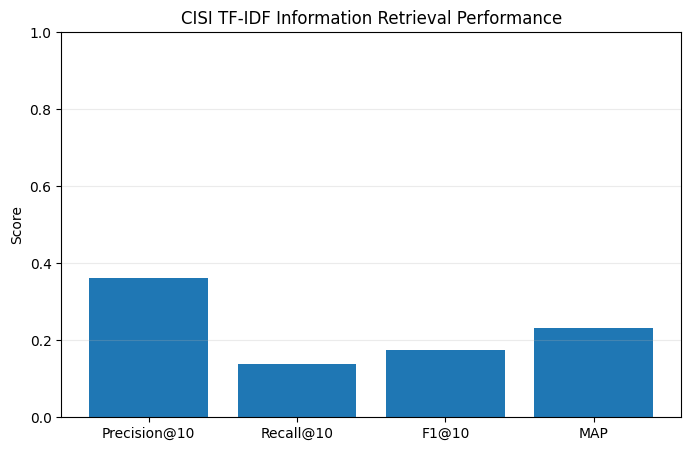

In [11]:
metrics = ["Precision@10", "Recall@10", "F1@10", "MAP"]
values = [
    evaluation_df["Precision@10"].mean(),
    evaluation_df["Recall@10"].mean(),
    evaluation_df["F1@10"].mean(),
    evaluation_df["Average_Precision"].mean()
]

plt.figure(figsize=(8, 5))
plt.bar(metrics, values)
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("CISI TF-IDF Information Retrieval Performance")
plt.grid(axis="y", alpha=0.25)
plt.show()


## 11. Interactive Custom Query

In [12]:
user_query = input("Enter your search query: ")
display(search(user_query, top_k=10))


,Rank,Document_ID,Similarity,Title,Snippet
0,1,1134,0.485889,Information Retrieval Learning,The statement of the problem and the results o...
1,2,716,0.257033,Reading Behavior of Chemists,Most discussions about the future design of ch...
2,3,344,0.252056,Current Problems in Reference Service,Current Problems in Reference Service is a col...
3,4,322,0.247427,The Community College Library,This study deals with the learning resources p...
4,5,1349,0.193034,Sources of Information in the Social Sciences,Documentation in the social sciences is varied...
5,6,847,0.176953,Library Instruction and the Development of the...,The purpose of a university education is defin...
6,7,258,0.175260,Classification and Indexing in Science,"The first problem, that of learning of a publi..."
7,8,1033,0.162308,The Making of a Library,A book like this is a cumulation of experience...
8,9,432,0.133155,Illustrative Computer Programming for Libraries,Illustrative Computer Programming is intended ...
9,10,124,0.127229,The User Interface in Interactive Systems,The digital computer has been used as a proble...


## Conclusion

This project demonstrates a complete classical information retrieval pipeline on the CISI collection. Documents and queries are preprocessed consistently, documents are indexed using TF-IDF, and cosine similarity is used to rank documents for a query. The provided relevance judgments enable objective evaluation using Precision, Recall, F1, Average Precision, and MAP.

### Limitations
TF-IDF is based mainly on lexical overlap. It may miss relevant documents that express the same concept with different vocabulary. Future work could compare this model with BM25, query expansion, or semantic embedding-based retrieval.
